# Unemployment Analysis with Python

## Objective

Perform exploratory data analysis on unemployment data
to uncover regional and temporal trends, with a focus
on the impact of COVID-19 on unemployment in India.

## Analysis

- Region-wise average unemployment
- Month-wise unemployment trends
- State-wise unemployment comparison
- COVID-19 impact analysis
- Employment and labour participation analysis

## Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the unemployment dataset

df = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Display the first 5 rows of the dataset

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 267
Number of columns: 9


In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    object 
 1    Date                                     267 non-null    object 
 2    Frequency                                267 non-null    object 
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    object 
 7   longitude                                 267 non-null    float64
 8   latitude                                  267 non-null    float64
dtypes: float64(4), int64(1), object(4)
memory usage: 18.9+ KB


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64


In [8]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267.000000,2.670000e+02,267.000000,267.000000,267.000000
mean,12.236929,1.396211e+07,41.681573,22.826048,80.532425
std,10.803283,1.336632e+07,7.845419,6.270731,5.831738
min,0.500000,1.175420e+05,16.770000,10.850500,71.192400
25%,4.845000,2.838930e+06,37.265000,18.112400,76.085600
50%,9.650000,9.732417e+06,40.390000,23.610200,79.019300
75%,16.755000,2.187869e+07,44.055000,27.278400,85.279900
max,75.850000,5.943376e+07,69.690000,33.778200,92.937600


In [9]:
# Clean the column names

df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


In [10]:
# Convert Date column to datetime format

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

print("Date converted successfully!")

Date converted successfully!


In [11]:
# Check the data type of Date column

print(df['Date'].dtype)

datetime64[ns]


In [12]:
# Check missing values after cleaning

print(df.isnull().sum())

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64


## Data Cleaning

The dataset was inspected for missing values and data types.
Column names were cleaned, and the Date column was converted
into datetime format to make time-based analysis easier.

In [13]:
# Calculate the average unemployment rate for each region

region_unemployment = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean()

print(region_unemployment)

Region
Andhra Pradesh       8.664000
Assam                4.856000
Bihar               19.471000
Chhattisgarh         7.819000
Delhi               18.414000
Goa                 12.167000
Gujarat              6.376000
Haryana             27.477000
Himachal Pradesh    16.065000
Jammu & Kashmir     16.477778
Jharkhand           19.539000
Karnataka            7.668000
Kerala               9.434000
Madhya Pradesh       6.854000
Maharashtra          7.979000
Meghalaya            3.866000
Odisha               6.462000
Puducherry          17.942000
Punjab              11.981000
Rajasthan           15.868000
Sikkim               9.792500
Tamil Nadu          12.187000
Telangana            6.833000
Tripura             25.055000
Uttar Pradesh        9.737000
Uttarakhand         11.156000
West Bengal         10.192000
Name: Estimated Unemployment Rate (%), dtype: float64


In [14]:
# Sort regions by average unemployment rate

region_unemployment = region_unemployment.sort_values(ascending=False)

region_unemployment.head(10)

Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Name: Estimated Unemployment Rate (%), dtype: float64

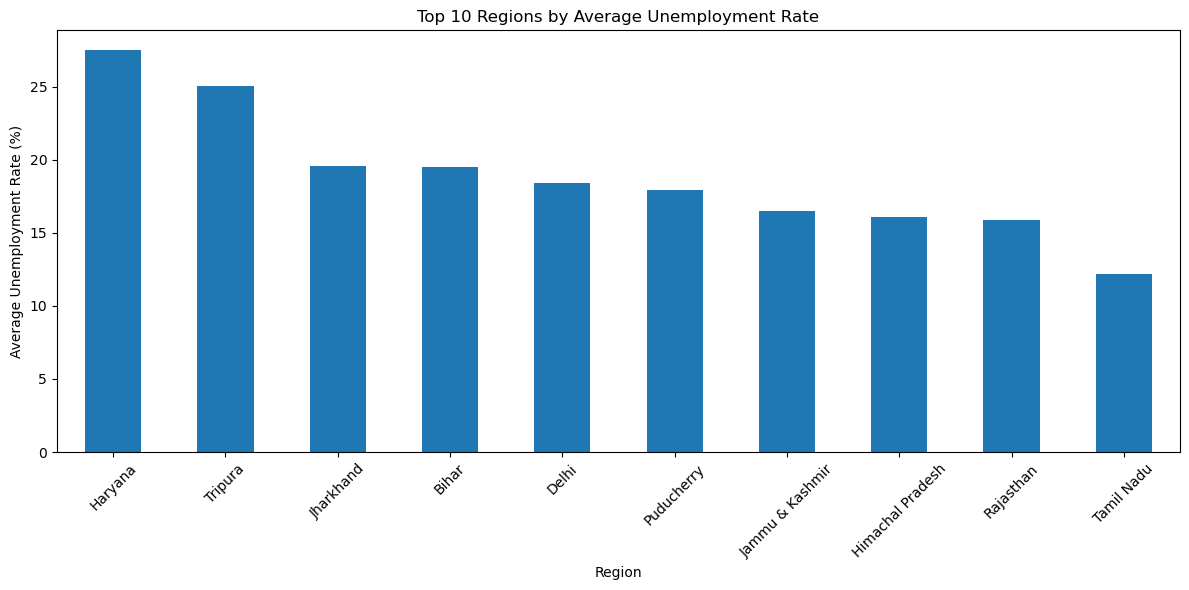

In [15]:
# Plot the top 10 regions with highest average unemployment rate

plt.figure(figsize=(12, 6))

region_unemployment.head(10).plot(kind='bar')

plt.title('Top 10 Regions by Average Unemployment Rate')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## Region-wise Unemployment Analysis

The average unemployment rate was calculated for each region.
The regions were then sorted to identify those with the highest
average unemployment rate.

The bar chart shows the top 10 regions with the highest average
unemployment rate in the dataset.

In [16]:
# Calculate the average unemployment rate for each region

region_unemployment = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean()

print(region_unemployment)

Region
Andhra Pradesh       8.664000
Assam                4.856000
Bihar               19.471000
Chhattisgarh         7.819000
Delhi               18.414000
Goa                 12.167000
Gujarat              6.376000
Haryana             27.477000
Himachal Pradesh    16.065000
Jammu & Kashmir     16.477778
Jharkhand           19.539000
Karnataka            7.668000
Kerala               9.434000
Madhya Pradesh       6.854000
Maharashtra          7.979000
Meghalaya            3.866000
Odisha               6.462000
Puducherry          17.942000
Punjab              11.981000
Rajasthan           15.868000
Sikkim               9.792500
Tamil Nadu          12.187000
Telangana            6.833000
Tripura             25.055000
Uttar Pradesh        9.737000
Uttarakhand         11.156000
West Bengal         10.192000
Name: Estimated Unemployment Rate (%), dtype: float64


In [17]:
# Sort regions by average unemployment rate

region_unemployment = region_unemployment.sort_values(ascending=False)

region_unemployment.head(10)

Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Name: Estimated Unemployment Rate (%), dtype: float64

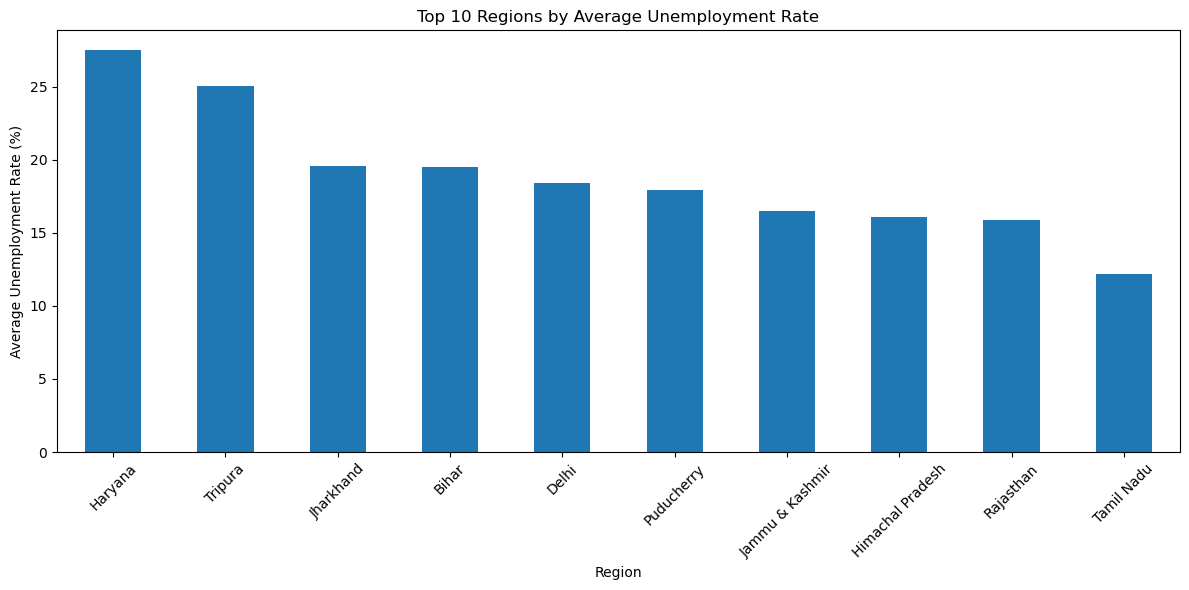

In [18]:
# Plot the top 10 regions with highest average unemployment rate

plt.figure(figsize=(12, 6))

region_unemployment.head(10).plot(kind='bar')

plt.title('Top 10 Regions by Average Unemployment Rate')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## Region-wise Unemployment Analysis

The average unemployment rate was calculated for each region.
The regions were then sorted to identify those with the highest
average unemployment rate.

The bar chart shows the top 10 regions with the highest average
unemployment rate in the dataset.

In [19]:
# Calculate the average unemployment rate for each month

monthly_unemployment = df.groupby('Date')['Estimated Unemployment Rate (%)'].mean()

print(monthly_unemployment)

Date
2020-01-31     9.196538
2020-02-29     9.266154
2020-03-31    10.782593
2020-04-30    22.236154
2020-05-31    23.244444
2020-06-30    10.911111
2020-07-31     9.834444
2020-08-31    10.313333
2020-09-30     8.705926
2020-10-31     8.026296
Name: Estimated Unemployment Rate (%), dtype: float64


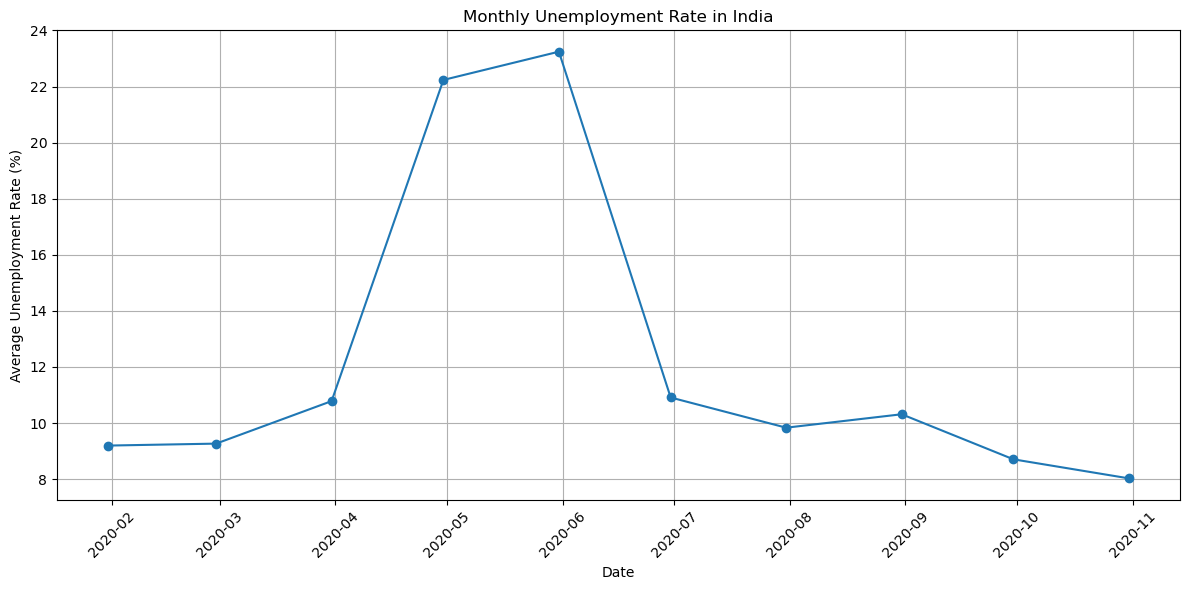

In [20]:
# Plot the monthly unemployment trend

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker='o'
)

plt.title('Monthly Unemployment Rate in India')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

## Month-wise Unemployment Trend

The monthly average unemployment rate was analyzed to understand
how unemployment changed over time.

The line chart helps identify increases and decreases in the
unemployment rate during the study period.

In [21]:
# Display all regions in the dataset

print(df['Region'].unique())

['Andhra Pradesh' 'Assam' 'Bihar' 'Chhattisgarh' 'Delhi' 'Goa' 'Gujarat'
 'Haryana' 'Himachal Pradesh' 'Jammu & Kashmir' 'Jharkhand' 'Karnataka'
 'Kerala' 'Madhya Pradesh' 'Maharashtra' 'Meghalaya' 'Odisha' 'Puducherry'
 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu' 'Telangana' 'Tripura'
 'Uttar Pradesh' 'Uttarakhand' 'West Bengal']


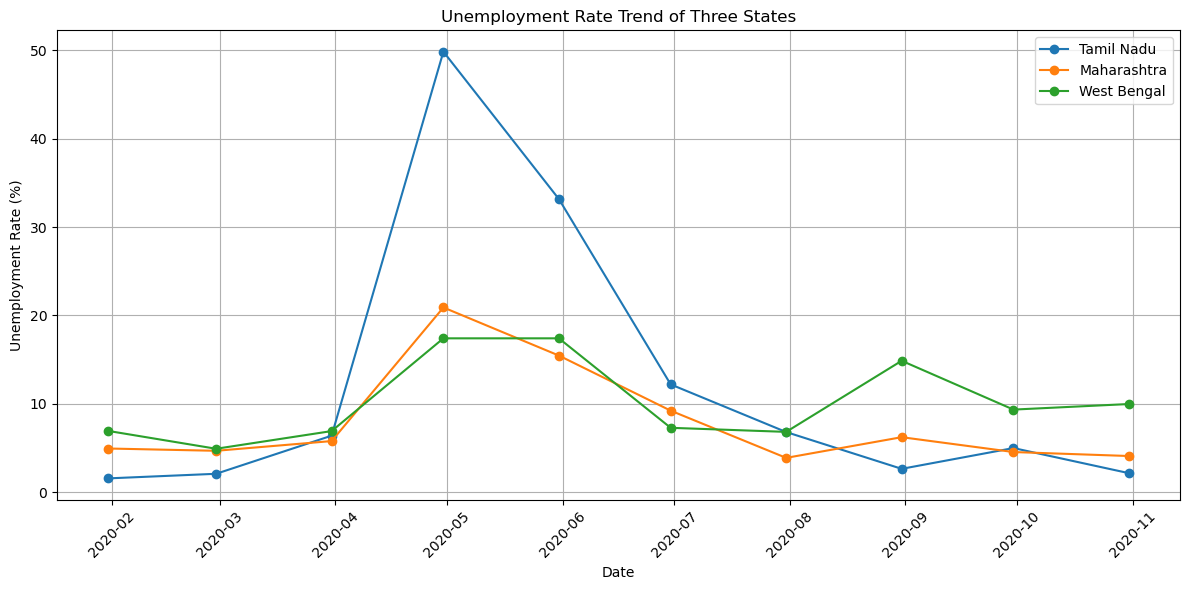

In [22]:
# Select three states for time-series analysis

selected_states = ['Tamil Nadu', 'Maharashtra', 'West Bengal']

plt.figure(figsize=(12, 6))

for state in selected_states:
    state_data = df[df['Region'] == state]
    
    plt.plot(
        state_data['Date'],
        state_data['Estimated Unemployment Rate (%)'],
        marker='o',
        label=state
    )

plt.title('Unemployment Rate Trend of Three States')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

## State-wise Time-Series Analysis

The unemployment rate trends of Tamil Nadu, Maharashtra,
and West Bengal were compared over time.

The line chart shows how unemployment changed in these
three states during the study period.

In [23]:
# Select important numerical columns

correlation_data = df[
    [
        'Estimated Unemployment Rate (%)',
        'Estimated Employed',
        'Estimated Labour Participation Rate (%)'
    ]
]

# Calculate correlation

correlation_matrix = correlation_data.corr()

print(correlation_matrix)

                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                 1.000000   
Estimated Employed                                             -0.245176   
Estimated Labour Participation Rate (%)                        -0.073540   

                                         Estimated Employed  \
Estimated Unemployment Rate (%)                   -0.245176   
Estimated Employed                                 1.000000   
Estimated Labour Participation Rate (%)           -0.047948   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                        -0.073540  
Estimated Employed                                                     -0.047948  
Estimated Labour Participation Rate (%)                                 1.000000  


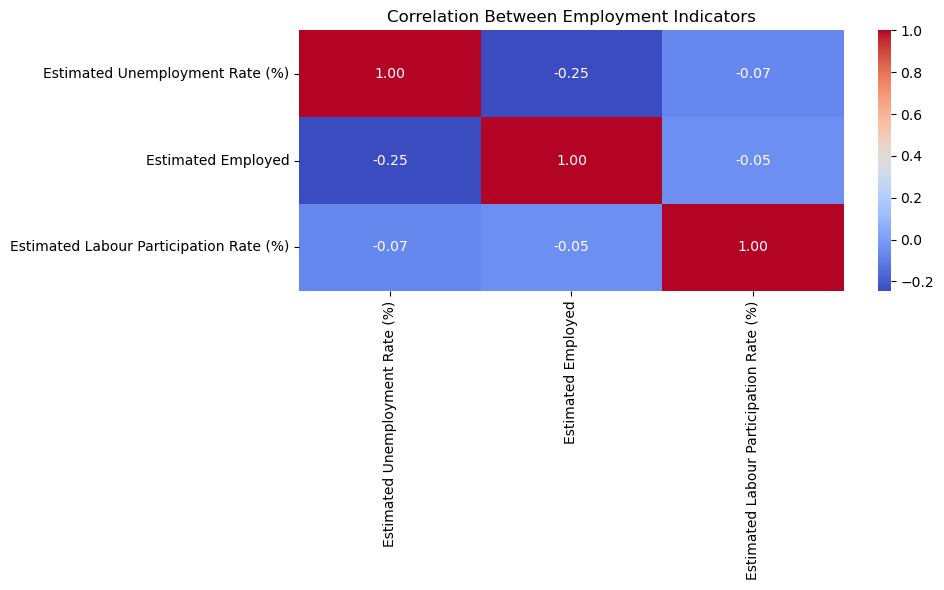

In [24]:
# Plot the correlation heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Employment Indicators')
plt.tight_layout()

plt.show()

## Correlation Analysis

A correlation heatmap was created to understand the relationship
between unemployment rate, estimated employment, and labour
participation rate.

The correlation values help identify whether the variables have
positive or negative relationships with each other.

In [25]:
# Create Pre-COVID and Post-COVID groups

pre_covid = df[df['Date'] < '2020-03-01']

post_covid = df[df['Date'] >= '2020-03-01']

print("Pre-COVID records:", len(pre_covid))
print("Post-COVID records:", len(post_covid))

Pre-COVID records: 52
Post-COVID records: 215


In [26]:
# Calculate average unemployment rate for both periods

pre_covid_rate = pre_covid['Estimated Unemployment Rate (%)'].mean()
post_covid_rate = post_covid['Estimated Unemployment Rate (%)'].mean()

print("Pre-COVID Average Unemployment Rate:",
      round(pre_covid_rate, 2), "%")

print("Post-COVID Average Unemployment Rate:",
      round(post_covid_rate, 2), "%")

Pre-COVID Average Unemployment Rate: 9.23 %
Post-COVID Average Unemployment Rate: 12.96 %


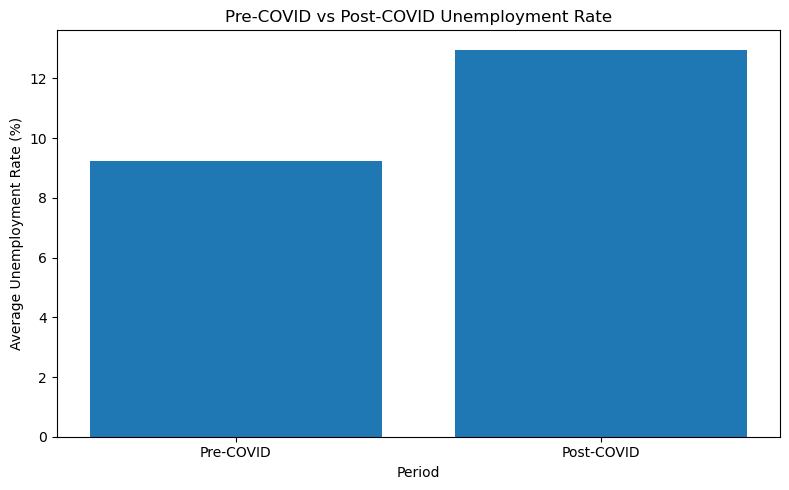

In [27]:
# Compare Pre-COVID and Post-COVID unemployment rates

periods = ['Pre-COVID', 'Post-COVID']
rates = [pre_covid_rate, post_covid_rate]

plt.figure(figsize=(8, 5))

plt.bar(periods, rates)

plt.title('Pre-COVID vs Post-COVID Unemployment Rate')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')

plt.tight_layout()
plt.show()

## COVID-19 Impact Analysis

The unemployment rate was compared between the Pre-COVID
and Post-COVID periods.

The comparison helps understand how unemployment changed
after the beginning of the COVID-19 period in 2020.

In [28]:
# Calculate average employment and labour participation

average_employed = df['Estimated Employed'].mean()
average_labour_participation = df['Estimated Labour Participation Rate (%)'].mean()

print("Average Estimated Employed:",
      round(average_employed, 2))

print("Average Labour Participation Rate:",
      round(average_labour_participation, 2), "%")

Average Estimated Employed: 13962105.72
Average Labour Participation Rate: 41.68 %


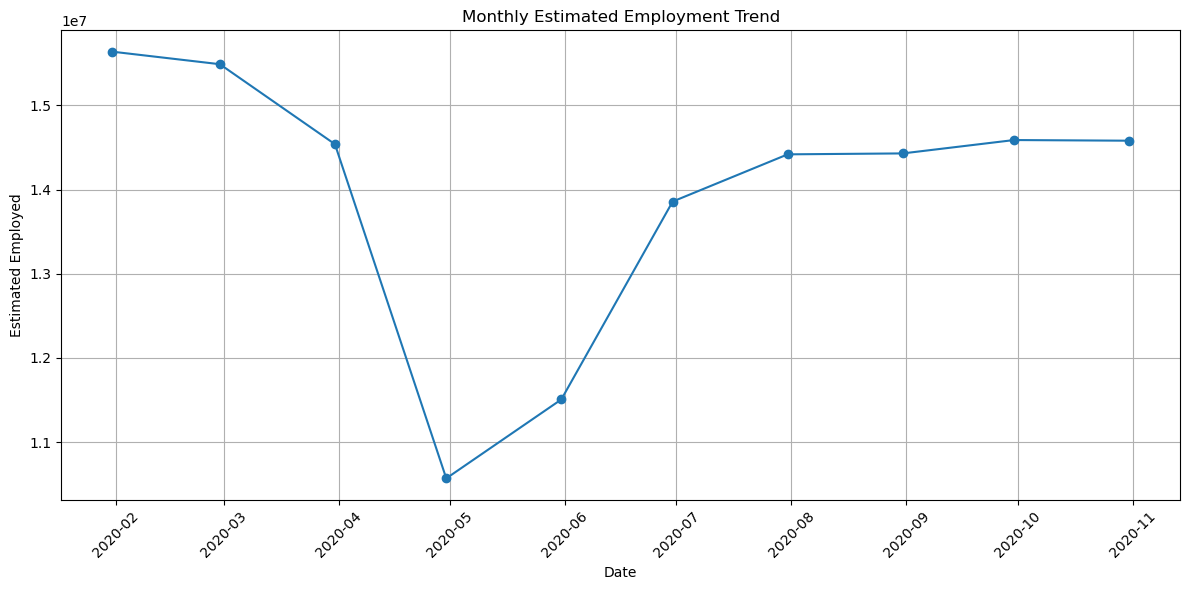

In [29]:
# Calculate monthly average employment

monthly_employment = df.groupby('Date')['Estimated Employed'].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_employment.index,
    monthly_employment.values,
    marker='o'
)

plt.title('Monthly Estimated Employment Trend')
plt.xlabel('Date')
plt.ylabel('Estimated Employed')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

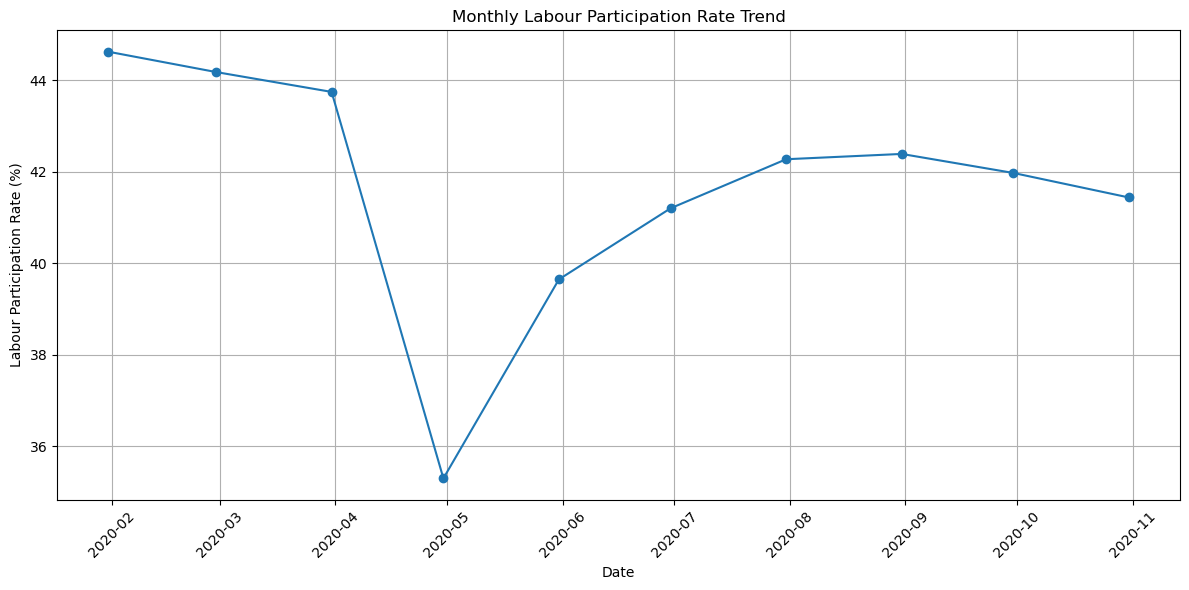

In [30]:
# Calculate monthly labour participation rate

monthly_labour = df.groupby('Date')['Estimated Labour Participation Rate (%)'].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_labour.index,
    monthly_labour.values,
    marker='o'
)

plt.title('Monthly Labour Participation Rate Trend')
plt.xlabel('Date')
plt.ylabel('Labour Participation Rate (%)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

## Employment and Labour Participation Analysis

The monthly trends of estimated employment and labour
participation rate were analyzed to understand changes
in employment conditions during the study period.

These trends can be compared with the unemployment rate
to understand the overall employment situation.

# Final Observations

## Key Findings

1. The unemployment rate varied significantly across different
   regions of India.

2. The monthly unemployment trend shows noticeable changes
   during the study period.

3. The unemployment rate increased sharply during the
   COVID-19 period, indicating the impact of the pandemic
   on employment conditions.

4. Tamil Nadu, Maharashtra, and West Bengal showed different
   unemployment trends during the study period.

5. The correlation heatmap helps understand the relationship
   between unemployment rate, estimated employment, and
   labour participation rate.

6. Employment and labour participation trends provide
   additional insights into the employment situation in India.

# Conclusion

This project analyzed unemployment data from different regions
of India using Python.

Exploratory Data Analysis was performed to understand regional
and monthly unemployment trends. Various visualizations such as
bar charts, line charts, and a correlation heatmap were used to
identify important patterns.

The analysis also compared Pre-COVID and Post-COVID unemployment
rates to understand the impact of COVID-19 on employment.

Overall, the project demonstrates how Python, Pandas, Matplotlib,
and Seaborn can be used to analyze real-world unemployment data
and extract meaningful insights.

# Project Summary

### Dataset
Unemployment in India

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Analysis Performed
- Data Cleaning
- Region-wise Unemployment Analysis
- Month-wise Trend Analysis
- State-wise Time-Series Analysis
- Correlation Analysis
- Pre-COVID vs Post-COVID Comparison
- Employment Analysis
- Labour Participation Analysis